# 📘 Explained copy — 03 Fraud detection (Module 3)

Study copy of `notebooks/03_fraud.ipynb`. Original cells unchanged (with outputs); above each is an **Explanation**:
*what it does · why this method · input → output · how to read the output vs alternatives*.

**Story for the report.** 30,000 transactions, **2.3% fraud** → accuracy is meaningless; we use PR-AUC, recall,
precision and above all **rupee cost** (₹10,000 per missed fraud, ₹500 per false alarm). We split **by time**
(60/20/20) because a bank only scores future transactions. The key signal is **amount ÷ the customer's own average**.
Three supervised models + Isolation Forest + a one-variable rule are compared. **Random forest** is chosen
(test PR-AUC 0.142 = 6× random, ROC-AUC 0.81). The alert threshold is picked from the **cost curve on validation**
and applied unchanged to test: investigate 7.5% of transactions, catch 51% of fraud, cost ₹8.98 lakh vs ₹14.4 lakh with
no model → **38% saving**. Isolation Forest catches far less (unusual ≠ fraudulent).

**Key numbers:** RF test ROC-AUC 0.805, PR-AUC 0.142 · threshold 0.534 · saving 37.6% · ₹90k saved per 1,000 txns ·
₹16.3 lakh/yr at file volume.

> ### 📘 Explanation — cell 0
> **What it is.** Business question (catch fraud without wasting money on false alarms), chain (probability + anomaly
> score → cost → cost-minimising threshold → saving), and the **time split 60/20/20**.
>
> **Why a time split + separate validation period.** Fraud patterns drift and the bank always scores *future*
> transactions; a random split would mix future patterns into training (look-ahead) and flatter results. Validation is
> used to pick both the model **and** the threshold, so the test period remains a clean, honest estimate.

# 03. Fraud detection (Module 3)

**Business question.** NovaFin processes thousands of transactions a day. Which ones should the fraud team
investigate, so that we catch most fraud **without** wasting money on false alarms?

**Chain.** Transaction data → fraud probability (supervised ML) and anomaly score (Isolation Forest)
→ expected operational cost (₹10,000 per missed fraud, ₹500 per false alarm) → cost-minimising alert threshold
→ saving vs no model (feeds the digital banking line in notebook 10).

**Brief tasks covered.**
1. EDA: fraud rate, by transaction type, amount, location, customer behaviour.
2. Supervised model on `Fraud_Flag`, compare models.
3. Unsupervised detection with Isolation Forest, compare with supervised.
4. Cost-based threshold that minimises expected operational cost.

**Validation design (important).** Fraud patterns drift over time and a bank only ever scores *future* transactions,
so we split **by time**, never randomly:
- **Train**: first 60% of the timeline (fit the models),
- **Validation**: next 20% (choose the model and the alert threshold),
- **Test**: last 20% (touched once, to report honest final numbers).

> ### 📘 Explanation — cell 1
> **What it does.** Loads helpers and sets output folders for Module 3.

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('03')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_03_Fraud_Detection/ and figures/Module_03_Fraud_Detection/


> ### 📘 Explanation — cell 2
> **What it does.** Imports logistic regression, random forest, histogram gradient boosting, **Isolation Forest**,
> scaler, one-hot encoder, ColumnTransformer and Pipeline.
>
> **Why pipelines.** Preprocessing (scaling/encoding) is fitted only on training data inside the pipeline → no leakage
> from validation/test into the scaler.

In [2]:
from sklearn.linear_model import LogisticRegression                       # model 1: transparent baseline
from sklearn.ensemble import RandomForestClassifier                       # model 2: bagged trees
from sklearn.ensemble import HistGradientBoostingClassifier               # model 3: boosted trees
from sklearn.ensemble import IsolationForest                              # unsupervised anomaly detector
from sklearn.preprocessing import StandardScaler, OneHotEncoder           # scaling and dummy variables
from sklearn.compose import ColumnTransformer                             # apply different prep to different columns
from sklearn.pipeline import Pipeline                                     # chain prep + model so nothing leaks
from scipy import stats                                                   # statistics helpers
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

> ### 📘 Explanation — cell 3
> **What it does.** Sets miss cost ₹10,000 and false-positive cost ₹500 (ratio **20:1**) and defines `score_report()`,
> which converts any score to a percentile rank and returns ROC-AUC, PR-AUC, KS.
>
> **Why ranks.** Isolation Forest scores and raw ratios are not probabilities; ranking metrics only need the order, so
> converting to ranks lets every method be compared on the same footing (calibration is meaningless for ranks).
>
> **Why the 20:1 ratio matters.** It means missing fraud is far worse than a false alarm → the optimal threshold will be
> low and the policy will investigate many transactions.

In [3]:
MISS_COST = ASSUMPTIONS['FRAUD_MISS_COST']               # ₹10,000 lost per fraud we fail to catch (brief)
FP_COST = ASSUMPTIONS['FRAUD_FALSE_POSITIVE_COST']       # ₹500 spent investigating a genuine transaction (brief)
def score_report(y, s, name):
    """Ranking metrics only. Works for any score (probability, anomaly score, raw ratio)."""
    r = binary_report(y, pd.Series(s).rank(pct=True).values, name)    # percentile rank keeps the ordering, fits in [0,1]
    return r[['ROC-AUC', 'PR-AUC', 'KS']]                              # calibration is meaningless for a rank

print('Missed fraud costs', MISS_COST, '| false alarm costs', FP_COST, '| ratio', MISS_COST / FP_COST)

Missed fraud costs 10000 | false alarm costs 500 | ratio 20.0


> ### 📘 Explanation — cell 4
> **What it does.** Loads transactions with parsed timestamps and **sorts by time** (required for the time split and for
> history-based features).
>
> **Output.** (30,000, 12) — columns include Amount, Type, Merchant, Location, Device, Account age, Historical average, Frequency, Fraud_Flag.

In [4]:
tx = load('transactions', parse_dates=['Timestamp'])     # 30,000 transactions
tx = tx.sort_values('Timestamp').reset_index(drop=True)  # time order matters for the split and behaviour features
print(tx.shape)                                          # rows, columns
tx.head()

(30000, 12)


,Transaction_ID,Customer_ID,Timestamp,Amount,Transaction_Type,Merchant_Category,Location,Device_ID,Account_Age_Months,Historical_Avg_Transaction,Transaction_Frequency,Fraud_Flag
0,5000001,200541,2025-01-01 00:00:00.000000000,2582.90,Payment,Retail,Chennai,11437,77,4650.19,8,0
1,5000002,201166,2025-01-01 00:29:08.218273942,1236.10,Payment,Travel,Pune,10504,170,9832.22,10,0
2,5000003,200479,2025-01-01 00:58:16.436547884,7909.31,Transfer,Investment,Hyderabad,11361,67,5655.09,8,0
3,5000004,201405,2025-01-01 01:27:24.654821827,41417.90,Transfer,Retail,Mumbai,10944,133,8045.82,9,0
4,5000005,202330,2025-01-01 01:56:32.873095769,10893.53,Withdrawal,Utilities,Kolkata,11100,62,13553.16,5,0


> ### 📘 Explanation — cell 5
> **Section header** – audit and EDA (Task 1).

## 1. Audit and exploratory analysis (Task 1)

> ### 📘 Explanation — cell 6
> **What it does.** Checks missing values, duplicate IDs, period, number of customers/devices, fraud count and rate.
>
> **Output.** 0 missing, 0 duplicates, 2025-01-01 → 2026-08-31, 2,500 customers, 1,500 devices, **684 frauds (2.28%)**.

In [5]:
print('Missing values :', int(tx.isna().sum().sum()))                       # expect 0
print('Duplicate IDs  :', int(tx.Transaction_ID.duplicated().sum()))         # expect 0
print('Period         :', tx.Timestamp.min().date(), 'to', tx.Timestamp.max().date())
print('Customers      :', tx.Customer_ID.nunique(), '| devices:', tx.Device_ID.nunique())
print('Frauds         :', int(tx.Fraud_Flag.sum()), '| fraud rate:', round(tx.Fraud_Flag.mean(), 4))

Missing values : 0
Duplicate IDs  : 0
Period         : 2025-01-01 to 2026-08-31
Customers      : 2500 | devices: 1500
Frauds         : 684 | fraud rate: 0.0228


> ### 📘 Explanation — cell 7
> **Why accuracy is useless.** "Never fraud" = 97.7% accuracy, 0 frauds caught. **PR-AUC** (random ≈ 0.023) focuses on
> the rare class; **recall** = share of fraud caught; **precision** = share of alerts that are real; **rupee cost** combines
> both with business weights. ROC-AUC alone can look good on imbalanced data even when precision is poor.

**Why accuracy is useless here.** With a 2.3% fraud rate, a "model" that says *never fraud* is 97.7% accurate and
catches nothing. We therefore use **PR-AUC** (precision-recall area; a random model scores ≈ the fraud rate, 0.023),
**recall** (share of fraud caught), **precision** (share of alerts that are real fraud) and, above all, **rupee cost**.

> ### 📘 Explanation — cell 8
> **What it does.** Creates `Amount_Ratio` = Amount / customer's historical average, `Hour`, and deciles of amount and
> ratio (for EDA only).
>
> **Why.** Fraud is about *unusual behaviour for this customer* — the ratio normalises each amount by the customer's own
> baseline (a classic behavioural feature).

In [6]:
tx['Amount_Ratio'] = tx.Amount / tx.Historical_Avg_Transaction   # how unusual is this amount for this customer?
tx['Hour'] = tx.Timestamp.dt.hour                                # time of day
tx['Amount_Decile'] = pd.qcut(tx.Amount, 10, labels=False) + 1   # 1 = smallest 10%, 10 = largest 10%
tx['Ratio_Decile'] = pd.qcut(tx.Amount_Ratio, 10, labels=False) + 1

> ### 📘 Explanation — cell 9
> **What it does.** Six bar charts of fraud rate by type, location, merchant, amount decile, ratio decile and hour, with
> the overall rate as a dashed line. Saves `fraud_eda.png`.
>
> **How to read.** Bars far above the dashed line = risky groups. Amount and ratio deciles rise steeply; categorical
> panels are flat.

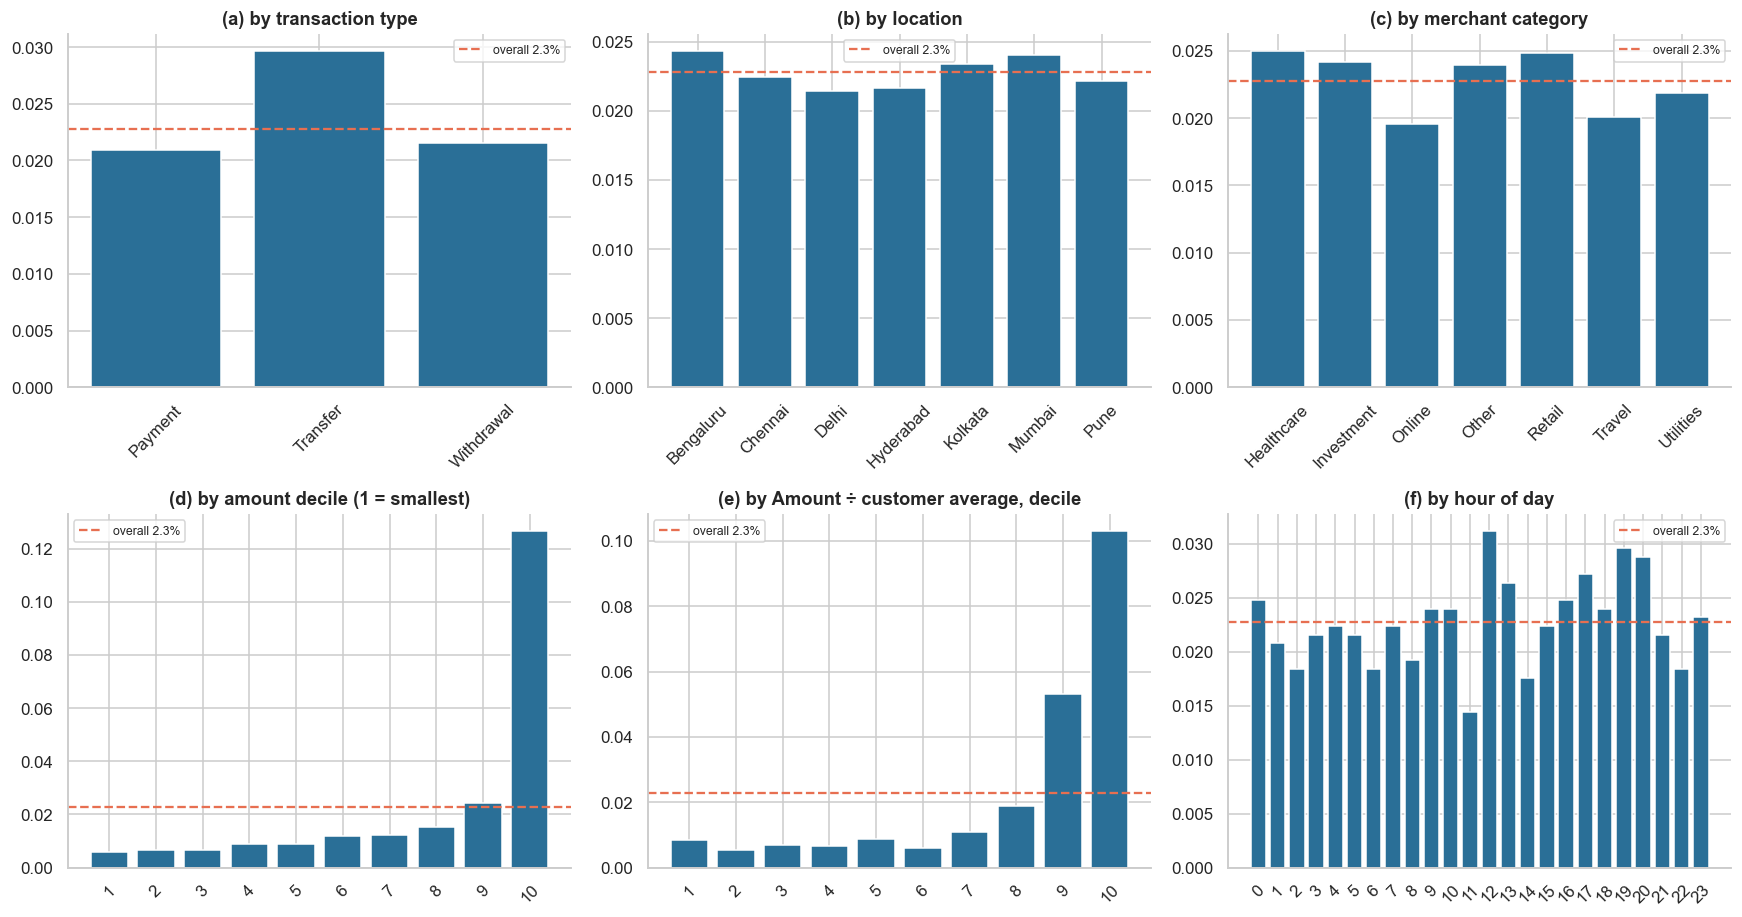

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))                          # six EDA panels
base = tx.Fraud_Flag.mean()                                             # overall fraud rate, drawn as a reference line
panels = [('Transaction_Type', '(a) by transaction type'), ('Location', '(b) by location'),
          ('Merchant_Category', '(c) by merchant category'), ('Amount_Decile', '(d) by amount decile (1 = smallest)'),
          ('Ratio_Decile', '(e) by Amount ÷ customer average, decile'), ('Hour', '(f) by hour of day')]
for a, (col, title) in zip(ax.ravel(), panels):
    r = tx.groupby(col).Fraud_Flag.mean()                               # fraud rate in each group
    a.bar(r.index.astype(str), r.values, color='#2a6f97')                # one bar per group
    a.axhline(base, ls='--', c='#e76f51', label=f'overall {base:.1%}')   # overall rate for comparison
    a.set_title(title); a.tick_params(axis='x', rotation=45); a.legend(fontsize=8)
plt.tight_layout(); savefig('fraud_eda'); plt.show()

> ### 📘 Explanation — cell 10
> **What it does.** For each variable: lowest and highest group fraud rate and **highest ÷ overall** (1.0 = nothing stands out).
>
> **Output.** Amount decile **5.6×**, ratio decile **4.5×**, hour 1.37×, type 1.30×, merchant 1.10×, location 1.07×.
>
> **How to read.** A one-number summary of the charts: amount-based features carry the signal; location/merchant are noise.

In [8]:
# How much does the fraud rate move across the groups of each variable? (max group rate vs min group rate)
spread = {}
for col in ['Transaction_Type', 'Location', 'Merchant_Category', 'Amount_Decile', 'Ratio_Decile', 'Hour']:
    r = tx.groupby(col).Fraud_Flag.mean()                               # fraud rate in each group
    spread[col] = {'lowest group rate': r.min(), 'highest group rate': r.max(),
                   'highest ÷ overall rate': r.max() / tx.Fraud_Flag.mean()}   # 1.0 = no group stands out
pd.DataFrame(spread).T.sort_values('highest ÷ overall rate', ascending=False).round(4)

,lowest group rate,highest group rate,highest ÷ overall rate
Amount_Decile,0.0060,0.1267,5.5556
Ratio_Decile,0.0053,0.1030,4.5175
Hour,0.0144,0.0312,1.3684
Transaction_Type,0.0209,0.0297,1.3023
Merchant_Category,0.0196,0.0250,1.0978
Location,0.0215,0.0244,1.0693


> ### 📘 Explanation — cell 11
> **What it does.** Median of key behaviour variables for genuine vs fraud transactions.
>
> **Output.** Median amount ₹6,411 vs **₹26,438**; amount ratio **1.17 vs 5.0**; account age and frequency identical.
>
> **How to read.** A typical fraud is 5× the customer's normal spend — the core behavioural signature.

In [9]:
# Customer behaviour: compare the typical genuine and fraudulent transaction
behaviour = tx.groupby('Fraud_Flag')[['Amount', 'Historical_Avg_Transaction', 'Amount_Ratio',
                                      'Account_Age_Months', 'Transaction_Frequency']].median()
behaviour.index = ['genuine (median)', 'fraud (median)']
behaviour.round(2)

,Amount,Historical_Avg_Transaction,Amount_Ratio,Account_Age_Months,Transaction_Frequency
genuine (median),6411.09,5524.34,1.17,90.0,9.0
fraud (median),26438.00,4507.31,5.00,93.0,9.0


> ### 📘 Explanation — cell 12
> **EDA conclusion.** Behavioural features (vs the customer's own normal) should carry the model; location, merchant and hour are likely noise.

**Reading the EDA.**
- The fraud rate is about **2.3%** and is flat across locations, merchant categories and hours of the day.
  Transfers are a little riskier than payments and withdrawals.
- The strongest pattern by far is **amount relative to the customer's own average**. In the top two deciles of
  `Amount ÷ Historical_Avg_Transaction` the fraud rate jumps to roughly 5–10%, and the median fraud is several times
  the customer's normal spend. Absolute amount matters too, but mostly because large amounts are also unusual ones.
- Account age and transaction frequency look similar for fraud and genuine transactions.

**Consequence.** Behavioural features (how this transaction compares with the customer's normal behaviour)
should carry the model. Location, merchant and hour are likely noise.

> ### 📘 Explanation — cell 13
> **Leakage-safe features.** Every feature must be known *at the moment of the transaction*; history features use only **earlier** transactions (`cumcount`, `diff` on time-sorted data). IDs and the target are excluded.

## 2. Features (leakage-safe)
Every feature must be known **at the moment the transaction happens**. Behaviour features that look at a customer's
history use **only earlier transactions** (`shift` / `cumcount` on time-sorted data), never later ones.

Excluded: `Transaction_ID`, `Customer_ID`, `Device_ID` (identifiers, not characteristics), `Fraud_Flag` (target),
and the decile columns made for the EDA.

> ### 📘 Explanation — cell 14
> **What it does.** `Log_Amount`, `Log_Ratio` (> 0 = above usual), `Night` (00–06h), `Weekend`.
>
> **Why logs.** Amounts are heavily right-skewed; logs make the scale roughly symmetric, which helps logistic regression
> (linear in log-amount) and makes large outliers less dominant.

In [10]:
tx['Log_Amount'] = np.log(tx.Amount)                                 # amounts are very skewed; log tames them
tx['Log_Ratio'] = np.log(tx.Amount_Ratio)                            # >0 means above the customer's usual spend
tx['Night'] = tx.Hour.isin(range(0, 6)).astype(int)                  # 00:00-05:59 flag
tx['Weekend'] = (tx.Timestamp.dt.dayofweek >= 5).astype(int)          # Saturday/Sunday flag

> ### 📘 Explanation — cell 15
> **What it does.** Per customer (time-sorted): number of prior transactions, hours since last transaction (first one
> filled with the median), **New_Device** and **New_Location** flags (first time this customer uses this device/city).
>
> **Why.** Standard fraud velocity/novelty features; computed with `cumcount`/`diff` so they only use the past (no leakage).
>
> **Output.** 99.6% of transactions are on a "new" device ⇒ in this synthetic data the device flag carries no information.

In [11]:
g = tx.groupby('Customer_ID')                                          # history per customer (data are time-sorted)
tx['Prior_Txns'] = g.cumcount()                                        # how many earlier transactions we have seen
tx['Hours_Since_Last'] = g.Timestamp.diff().dt.total_seconds() / 3600   # gap since this customer's previous txn
tx['Hours_Since_Last'] = tx.Hours_Since_Last.fillna(tx.Hours_Since_Last.median())   # first txn: use a typical gap
tx['New_Device'] = (tx.groupby(['Customer_ID', 'Device_ID']).cumcount() == 0).astype(int)    # device not seen before
tx['New_Location'] = (tx.groupby(['Customer_ID', 'Location']).cumcount() == 0).astype(int)   # city not seen before
print('Share of transactions on a device the customer never used before:', round(tx.New_Device.mean(), 3))

Share of transactions on a device the customer never used before: 0.996


> ### 📘 Explanation — cell 16
> **Note.** Device switching on almost every transaction makes 'new device' useless here (in real banks it is a strong signal). Kept to show it was tested.

*Note:* customers switch devices almost every transaction in this synthetic file (≈ 12 devices per customer
for ≈ 12 transactions). So "new device", usually a strong fraud signal in real banks, cannot help here. We keep it
to show that we tested it.

> ### 📘 Explanation — cell 17
> **What it does.** Final feature list: 11 numeric + 3 categorical = **14 features**.

In [12]:
NUM = ['Log_Amount', 'Log_Ratio', 'Account_Age_Months', 'Transaction_Frequency', 'Hour', 'Night', 'Weekend',
       'Prior_Txns', 'Hours_Since_Last', 'New_Device', 'New_Location']          # numeric features
CAT = ['Transaction_Type', 'Merchant_Category', 'Location']                      # categorical features
FEATURES = NUM + CAT
print(len(FEATURES), 'features')

14 features


> ### 📘 Explanation — cell 18
> **Section header** – time-based split.

## 3. Time-based split

> ### 📘 Explanation — cell 19
> **What it does.** Cuts the time-ordered data at 60% and 80%: train / validation / test; prints dates, rows, frauds, rate.
>
> **Output.** Train 2025-01 → 2025-12 (18,000 rows, 411 frauds) · validation 2025-12 → 2026-05 (6,000, 129) ·
> test 2026-05 → 2026-08 (6,000, **144** frauds). Fraud rates 2.28% / 2.15% / 2.40% — stable over time.

In [13]:
n = len(tx)                                         # 30,000 rows in time order
i_val, i_test = int(n * 0.60), int(n * 0.80)        # cut points at 60% and 80% of the timeline
train, val, test = tx.iloc[:i_val], tx.iloc[i_val:i_test], tx.iloc[i_test:]
for name, part in [('train', train), ('validation', val), ('test', test)]:
    print(f'{name:<11} {part.Timestamp.min().date()} to {part.Timestamp.max().date()} | rows {len(part):>6} | frauds {int(part.Fraud_Flag.sum()):>4} | rate {part.Fraud_Flag.mean():.4f}')

train       2025-01-01 to 2025-12-31 | rows  18000 | frauds  411 | rate 0.0228
validation  2025-12-31 to 2026-05-01 | rows   6000 | frauds  129 | rate 0.0215
test        2026-05-01 to 2026-08-31 | rows   6000 | frauds  144 | rate 0.0240


> ### 📘 Explanation — cell 20
> **What it does.** Splits each period into X (features) and y (Fraud_Flag). Roles: fit on train, choose model/threshold on validation, report on test.

In [14]:
X_tr, y_tr = train[FEATURES], train.Fraud_Flag      # fit on these
X_va, y_va = val[FEATURES], val.Fraud_Flag          # choose model and threshold on these
X_te, y_te = test[FEATURES], test.Fraud_Flag        # report final results on these

> ### 📘 Explanation — cell 21
> **Models.** Three of rising flexibility. Imbalance handling: `class_weight='balanced'` (LR), `'balanced_subsample'` (RF); GB relies on ranking and the cost threshold does the rest. (SMOTE is an alternative; class weights are simpler and do not create synthetic rows.)

## 4. Supervised models (Task 2)
Three models of rising flexibility. The logistic regression uses `class_weight='balanced'` so the rare fraud class
is not ignored. The tree models handle imbalance through their probability ranking; the threshold step later
decides where to cut.

> ### 📘 Explanation — cell 22
> **What it does.** Preprocessing: scale numeric, one-hot categorical. Models: balanced logistic regression; random forest
> (400 trees, min leaf 20, balanced subsample); gradient boosting (depth 3, lr 0.05, 300 iterations).
>
> **Why these settings.** `min_samples_leaf=20` stops the forest from memorising the ~400 training frauds; class
> weighting up-weights fraud so the trees/loss pay attention to the rare class.

In [15]:
pre = ColumnTransformer([('num', StandardScaler(), NUM),                                  # scale numeric columns
                         ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])          # dummies for categories

models = {
    'Logistic regression': Pipeline([('pre', pre), ('m', LogisticRegression(class_weight='balanced', max_iter=3000))]),
    'Random forest': Pipeline([('pre', pre), ('m', RandomForestClassifier(n_estimators=400, min_samples_leaf=20,
                                                                         class_weight='balanced_subsample',
                                                                         n_jobs=-1, random_state=SEED))]),
    'Gradient boosting': Pipeline([('pre', pre), ('m', HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                                                    max_iter=300, random_state=SEED))]),
}

> ### 📘 Explanation — cell 23
> **What it does.** Fits each model on train; scores validation; reports ROC-AUC, PR-AUC, KS, calibration gap.
>
> **Output.** ROC-AUC LR 0.781 / RF 0.776 / GB 0.785; **PR-AUC 0.0996 / 0.108 / 0.094**; calibration gap 0.37 / 0.17 / 0.005.
>
> **How to read.** ROC-AUCs are tied, but PR-AUC (the right metric for a 2% class) favours RF. The huge LR calibration gap
> comes from class weighting, which **inflates probabilities** — important later (theoretical 4.8% threshold fails).

In [16]:
fitted = {name: m.fit(X_tr, y_tr) for name, m in models.items()}                     # train each model on the train period
val_prob = {name: m.predict_proba(X_va)[:, 1] for name, m in fitted.items()}         # scores on the validation period
val_rep = pd.DataFrame({name: binary_report(y_va, p, name) for name, p in val_prob.items()}).T
val_rep[['ROC-AUC', 'PR-AUC', 'KS', 'Calib. gap']].round(4)                           # compare on validation

,ROC-AUC,PR-AUC,KS,Calib. gap
Logistic regression,0.7806,0.0996,0.4983,0.3701
Random forest,0.7760,0.1081,0.4821,0.1660
Gradient boosting,0.7847,0.0941,0.4848,0.0054


> ### 📘 Explanation — cell 24
> **What it does.** Selection rule: simplest model unless a more complex one beats it by > 0.005 **PR-AUC** on validation.
>
> **Output.** Best = chosen = **Random forest** (0.108 vs 0.0996 for LR → +0.0085 > 0.005).
>
> **Why PR-AUC here (not ROC-AUC as in 02).** With 2% positives, PR-AUC reflects precision among alerts — what the fraud
> team actually experiences.

In [17]:
# Selection rule: simplest model wins unless a more complex one beats it by > 0.005 PR-AUC on validation.
order = ['Logistic regression', 'Random forest', 'Gradient boosting']                  # simplest first
best = val_rep['PR-AUC'].idxmax()                                                       # highest validation PR-AUC
chosen = next(m for m in order if val_rep.loc[best, 'PR-AUC'] - val_rep.loc[m, 'PR-AUC'] <= 0.005)
print('best on validation:', best, '| chosen (simplicity rule):', chosen)

best on validation: Random forest | chosen (simplicity rule): Random forest


> ### 📘 Explanation — cell 25
> **Isolation Forest (Task 3).** Unsupervised: never sees labels; isolates points with random splits — points isolated in few splits are anomalous. Numeric behaviour features only; fitted on the training period.

## 5. Unsupervised detection: Isolation Forest (Task 3)
Isolation Forest never sees `Fraud_Flag`. It isolates points with random splits; points that are isolated in few
splits are **unusual**. We give it the numeric behaviour features only (it cannot use text categories) and fit it on
the training period. Its anomaly score is then compared with the supervised probability.

> ### 📘 Explanation — cell 26
> **What it does.** Scales 6 numeric features and fits `IsolationForest(300 trees)` on train; anomaly score = −decision_function
> (higher = more unusual). Scores validation and test.
>
> **Output (validation).** ROC-AUC **0.684**, PR-AUC **0.048**, KS 0.30.
>
> **How to read vs supervised.** Better than random (0.023) but less than half the supervised PR-AUC. Anomaly detection
> finds *unusual* transactions, but most unusual transactions are genuine. Its value: it needs no labels and can catch
> **new** fraud patterns.

In [18]:
IF_FEATURES = ['Log_Amount', 'Log_Ratio', 'Account_Age_Months', 'Transaction_Frequency', 'Hour', 'Hours_Since_Last']
iso = Pipeline([('sc', StandardScaler()),                                                    # put features on one scale
                ('if', IsolationForest(n_estimators=300, contamination='auto', random_state=SEED))])
iso.fit(train[IF_FEATURES])                                                                  # no labels used
anom = lambda d: -iso.decision_function(d[IF_FEATURES])                                      # higher = more unusual
val_anom, test_anom = anom(val), anom(test)                                                  # scores per period
print('Isolation Forest on validation:')
print(score_report(y_va, val_anom, 'Isolation Forest').round(4))

Isolation Forest on validation:
ROC-AUC    0.6841
PR-AUC     0.0481
KS         0.3033
Name: Isolation Forest, dtype: float64


> ### 📘 Explanation — cell 27
> **What it does.** Benchmark with no model: rank transactions by `Log_Ratio` alone.
>
> **Output.** ROC-AUC **0.765**, PR-AUC 0.103 — almost as good as LR!
>
> **Why this matters.** Always compare ML with a simple business rule: it shows how much ML *adds* (here, modest — most
> of the signal is the amount ratio).

In [19]:
# Simplest possible rule, as a sanity benchmark: rank by Amount ÷ customer average only (no model at all)
print('Single rule (Amount ratio) on validation:')
print(score_report(y_va, val.Log_Ratio, 'Amount ratio rule').round(4))

Single rule (Amount ratio) on validation:
ROC-AUC    0.7650
PR-AUC     0.1029
KS         0.4957
Name: Amount ratio rule, dtype: float64


> ### 📘 Explanation — cell 28
> **Section header** – final scores on the untouched test period.

## 6. Final scores on the untouched test period

> ### 📘 Explanation — cell 29
> **What it does.** Scores test with all 5 methods and reports ROC-AUC, PR-AUC, KS.
>
> **Output.** RF **0.805 / 0.142 / 0.542**; GB 0.808 / 0.127; LR 0.775 / 0.094; Isolation Forest 0.623 / 0.044;
> amount-ratio rule 0.772 / 0.094.
>
> **How to read.** RF PR-AUC 0.142 ≈ **6× random (0.024)**. RF/GB beat the one-variable rule mainly on PR-AUC
> (interactions of amount, ratio, history). The validation choice (RF) holds up on test → selection was not lucky.

In [20]:
test_scores = {name: m.predict_proba(X_te)[:, 1] for name, m in fitted.items()}       # supervised probabilities
test_scores['Isolation Forest'] = test_anom                                              # unsupervised score
test_scores['Amount ratio rule'] = test.Log_Ratio.values                                 # one-variable rule
test_rep = pd.DataFrame({k: score_report(y_te, v, k) for k, v in test_scores.items()}).T
test_rep[['ROC-AUC', 'PR-AUC', 'KS']].round(4)

,ROC-AUC,PR-AUC,KS
Logistic regression,0.7753,0.0937,0.4805
Random forest,0.8053,0.1422,0.5418
Gradient boosting,0.8077,0.1265,0.5330
Isolation Forest,0.6229,0.0436,0.1934
Amount ratio rule,0.7723,0.0940,0.5168


> ### 📘 Explanation — cell 30
> **What it does.** ROC and precision–recall curves for all methods on test (`fraud_curves.png`).
>
> **How to read.** PR curve: start of the curve (low recall) shows precision at small alert volumes; the grey line = random precision 2.4%.

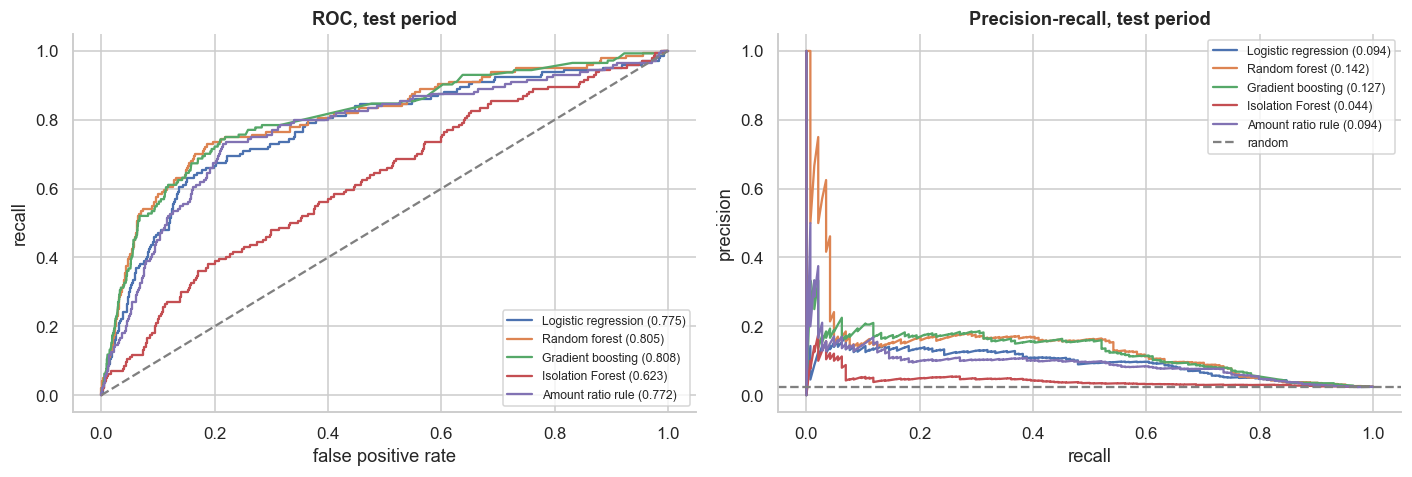

In [21]:
from sklearn.metrics import roc_curve, precision_recall_curve        # curve helpers
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_te, s); ax[0].plot(fpr, tpr, label=f"{k} ({test_rep.loc[k, 'ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_te, s); ax[1].plot(rc, pr, label=f"{k} ({test_rep.loc[k, 'PR-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], '--', c='grey'); ax[0].set(xlabel='false positive rate', ylabel='recall', title='ROC, test period')
ax[1].axhline(y_te.mean(), ls='--', c='grey', label='random'); ax[1].set(xlabel='recall', ylabel='precision', title='Precision-recall, test period')
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); savefig('fraud_curves'); plt.show()

> ### 📘 Explanation — cell 31
> **Comparison under equal alert budget.** Both methods investigate the top 5% of test transactions — a fair operational comparison.

### Supervised vs anomaly detection: do they flag the same transactions?
Give both methods the same **alert budget** (investigate the top 5% of test transactions) and compare what they catch.

> ### 📘 Explanation — cell 32
> **What it does.** Takes the top 300 (5%) by RF and by Isolation Forest; counts frauds caught, overlap, recall, precision, and the union.
>
> **Output.** RF catches **51** (recall 35%, precision 17%); IF catches **15** (10%, 5%); overlap only 61 of 300; union catches 56.
>
> **How to read.** IF adds only 5 extra frauds for 239 extra alerts ⇒ not cost-effective as a primary tool; it is a
> **second line of defence** for novel patterns.

In [22]:
k = int(len(test) * 0.05)                                                     # alert budget: top 5% of transactions
top_sup = set(np.argsort(-test_scores[chosen])[:k])                           # positions flagged by the chosen model
top_iso = set(np.argsort(-test_anom)[:k])                                     # positions flagged by Isolation Forest
fraud_pos = set(np.where(y_te.values == 1)[0])                                # positions that are real fraud
cmp = pd.DataFrame({
    'alerts': [k, k, len(top_sup | top_iso)],
    'frauds caught': [len(top_sup & fraud_pos), len(top_iso & fraud_pos), len((top_sup | top_iso) & fraud_pos)],
}, index=[chosen, 'Isolation Forest', 'union of both'])
cmp['recall'] = cmp['frauds caught'] / len(fraud_pos)                          # share of all test fraud caught
cmp['precision'] = cmp['frauds caught'] / cmp.alerts                           # share of alerts that were fraud
print('overlap of the two alert lists:', len(top_sup & top_iso), 'of', k)
cmp.round(3)

overlap of the two alert lists: 61 of 300


,alerts,frauds caught,recall,precision
Random forest,300,51,0.354,0.170
Isolation Forest,300,15,0.104,0.050
union of both,539,56,0.389,0.104


> ### 📘 Explanation — cell 33
> **Why SHAP.** Investigators and auditors must know *why* a transaction was flagged (explainability / regulation).

## 7. Explain the chosen model (SHAP)
Investigators and auditors need to know *why* a transaction was flagged. SHAP gives each feature's push on the
fraud probability for each transaction.

> ### 📘 Explanation — cell 34
> **What it does.** Extracts the fitted preprocessor and RF; uses **TreeExplainer** (exact and fast for tree models)
> with 300 background and 400 test transactions; keeps the fraud class; beeswarm plot (`fraud_shap.png`).
>
> **Why TreeExplainer.** For trees, SHAP values can be computed exactly in polynomial time; the model-agnostic explainer is
> only used if logistic regression had been chosen.

Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


 12%|==                  | 96/800 [00:11<01:20]       

 14%|===                 | 109/800 [00:12<01:16]       

 14%|===                 | 116/800 [00:13<01:16]       

 16%|===                 | 124/800 [00:14<01:16]       

 17%|===                 | 135/800 [00:15<01:13]       

... (44 outputs left out)

 94%|=================== | 750/800 [01:00<00:04]       

 95%|=================== | 761/800 [01:01<00:03]       

 97%|=================== | 773/800 [01:02<00:02]       

 98%|===================| 788/800 [01:03<00:00]       

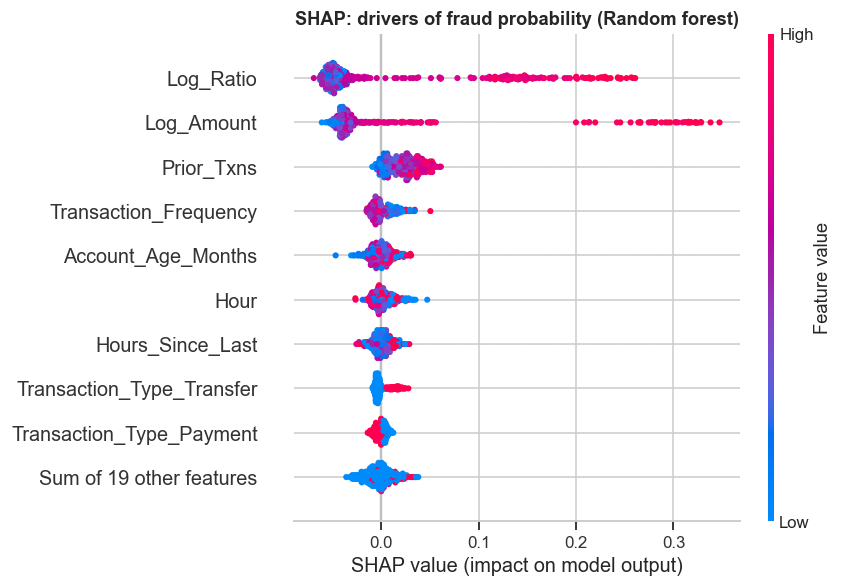

In [23]:
import shap                                                                           # explanation library
prep = fitted[chosen].named_steps['pre']                                              # the fitted preprocessing step
clf = fitted[chosen].named_steps['m']                                                 # the fitted model
names = [c.split('__', 1)[1] for c in prep.get_feature_names_out()]                   # readable feature names
bg = pd.DataFrame(prep.transform(X_tr.sample(300, random_state=SEED)), columns=names)  # background sample
ex = pd.DataFrame(prep.transform(X_te.sample(400, random_state=SEED)), columns=names)  # transactions to explain
if chosen == 'Logistic regression':
    sv = shap_importance(lambda a: clf.predict_proba(a)[:, 1], bg, ex)                 # model-agnostic SHAP (fast for linear)
else:
    sv = shap.TreeExplainer(clf, bg)(ex)                                               # exact and fast SHAP for tree models
    if sv.values.ndim == 3: sv = sv[:, :, 1]                                           # keep the 'fraud' class only
shap.plots.beeswarm(sv, max_display=10, show=False)                                   # direction and size of effects
plt.title(f'SHAP: drivers of fraud probability ({chosen})'); plt.tight_layout(); savefig('fraud_shap'); plt.show()

> ### 📘 Explanation — cell 35
> **What it does.** Ranks features by mean |SHAP|.
>
> **Output.** Log_Ratio **0.076**, Log_Amount 0.061, Prior_Txns 0.023, then small: frequency, account age, hour, hours since last, Transfer.
>
> **How to read.** Confirms the EDA: unusual amount vs the customer's norm dominates; device/location add nothing.

In [24]:
imp = pd.Series(np.abs(sv.values).mean(0), index=names).sort_values(ascending=False)   # mean |SHAP| per feature
imp.head(8).round(4).to_frame('mean |SHAP|')

,mean |SHAP|
Log_Ratio,0.0762
Log_Amount,0.0613
Prior_Txns,0.0231
Transaction_Frequency,0.0081
Account_Age_Months,0.0080
Hour,0.0071
Hours_Since_Last,0.0063
Transaction_Type_Transfer,0.0054


> ### 📘 Explanation — cell 36
> **Cost-based threshold (Task 4).** Cost(t) = 10,000 × missed + 500 × false alarms.
> Theory: investigate if p·10,000 > (1−p)·500 ⇒ **p > 4.8%** — valid *only if probabilities are calibrated*. Ours are
> not (class weighting), so we **scan thresholds on validation**, choose the cheapest, apply it unchanged to test.

## 8. Cost-based threshold (Task 4)
For any alert threshold *t*: transactions with score ≥ *t* are investigated.

$$\text{Cost}(t) = 10{,}000 \times \text{missed frauds}(t) + 500 \times \text{false alarms}(t)$$

**Theory check.** If the probability *p* were perfectly calibrated (ours are not: class weighting inflates them), investigating pays when
$p \times 10{,}000 > (1-p) \times 500$, i.e. when $p > 500 / 10{,}500 \approx 4.8\%$. We do not rely on that: we
**scan** thresholds on the **validation** period, pick the cheapest, and then apply it unchanged to the **test** period.

> ### 📘 Explanation — cell 37
> **What it does.** `cost_at()` computes alerts, caught, missed, false alarms and cost at a threshold; `scan()` evaluates
> 801 quantile thresholds.
>
> **Why quantile candidates.** They cover every alert volume from 0% to 100% evenly, regardless of score scale (works
> for probabilities and anomaly scores).

In [25]:
def cost_at(y, score, t):
    """Operational cost and confusion counts when every transaction with score >= t is investigated."""
    alert = score >= t                                      # which transactions are investigated
    fn = int(((~alert) & (y == 1)).sum())                   # frauds we miss
    fp = int((alert & (y == 0)).sum())                      # genuine transactions we investigate
    tp = int((alert & (y == 1)).sum())                      # frauds we catch
    return {'threshold': t, 'alerts': int(alert.sum()), 'caught': tp, 'missed': fn, 'false_alarms': fp,
            'cost': MISS_COST * fn + FP_COST * fp}

def scan(y, score):
    """Cost for every candidate threshold (each distinct score quantile)."""
    cands = np.unique(np.quantile(score, np.linspace(0, 1, 801)))   # 801 candidate cut-offs
    return pd.DataFrame([cost_at(np.asarray(y), np.asarray(score), t) for t in cands])

> ### 📘 Explanation — cell 38
> **What it does.** Scans cost curves on validation for RF and Isolation Forest and picks each one's cheapest threshold.
>
> **Output.** RF threshold **0.534**; Isolation Forest 0.0755.
>
> **How to read.** 0.534 is far above the theoretical 4.8% — because RF's class-balanced probabilities are inflated.

In [26]:
val_curves = {'supervised': scan(y_va, val_prob[chosen]),           # chosen model on validation
              'isolation': scan(y_va, val_anom)}                     # Isolation Forest on validation
best_t = {k: c.loc[c.cost.idxmin(), 'threshold'] for k, c in val_curves.items()}   # cheapest threshold per method
print('cost-minimising threshold chosen on validation:', {k: round(v, 4) for k, v in best_t.items()})

cost-minimising threshold chosen on validation: {'supervised': np.float64(0.534), 'isolation': np.float64(0.0755)}


> ### 📘 Explanation — cell 39
> **What it does.** Plots validation cost (₹ lakh) vs share of transactions investigated for both methods, with the 'no model' line (`fraud_cost_curve.png`). The minimum of the U-shaped curve is the optimal alert volume.

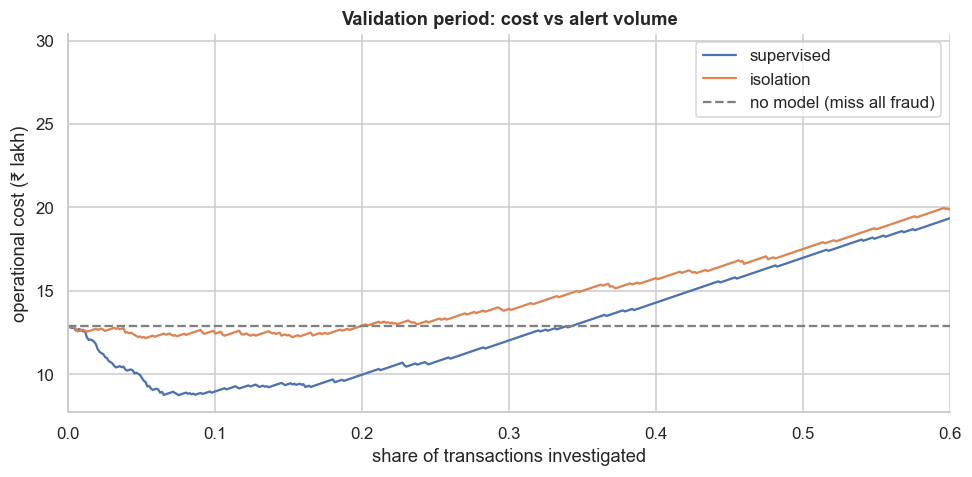

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, c in val_curves.items():
    share = c.alerts / len(val)                                                        # share of transactions investigated
    ax.plot(share, c.cost / 1e5, label=k)                                              # cost in ₹ lakh
ax.axhline(MISS_COST * y_va.sum() / 1e5, ls='--', c='grey', label='no model (miss all fraud)')
ax.set(xlabel='share of transactions investigated', ylabel='operational cost (₹ lakh)', title='Validation period: cost vs alert volume')
ax.set_xlim(0, 0.6); ax.legend(); plt.tight_layout(); savefig('fraud_cost_curve'); plt.show()

> ### 📘 Explanation — cell 40
> **What it does.** Applies validation thresholds to test and compares with simple policies.
>
> **Output.**
> | Policy | Alerts | Caught | Cost (₹) | Saving |
> |---|---|---|---|---|
> | No model | 0 | 0 | 14.4 lakh | 0 |
> | Investigate everything | 6,000 | 144 | 29.3 lakh | −103% |
> | **RF @ validation threshold** | **449** | **73** | **8.98 lakh** | **37.6%** |
> | Isolation Forest | 275 | 14 | 14.3 lakh | 0.7% |
> | RF @ theory 4.8% | 5,923 | 143 | 29.0 lakh | −101% |
>
> **How to read.** The RF policy catches 51% of fraud with 16% precision and beats both extremes. The theory threshold
> flags almost everything — proof that uncalibrated probabilities must not be plugged into the formula.

In [28]:
# Apply the validation thresholds to the untouched test period and compare with simple policies.
yt = y_te.values                                                                          # test labels as an array
rows = {
    'No model (investigate nothing)': cost_at(yt, np.zeros(len(yt)), 1.0),               # every fraud is missed
    'Investigate everything': cost_at(yt, np.ones(len(yt)), 0.0),                         # every txn investigated
    f'{chosen} @ validation threshold': cost_at(yt, test_scores[chosen], best_t['supervised']),
    'Isolation Forest @ validation threshold': cost_at(yt, test_anom, best_t['isolation']),
    f'{chosen} @ theory threshold 4.8%': cost_at(yt, test_scores[chosen], FP_COST / (FP_COST + MISS_COST)),
}
res_tbl = pd.DataFrame(rows).T
res_tbl['recall'] = res_tbl.caught / yt.sum()                                             # share of fraud caught
res_tbl['precision'] = res_tbl.caught / res_tbl.alerts.replace(0, np.nan)                 # share of alerts that are fraud
res_tbl['saving vs no model'] = 1 - res_tbl.cost / res_tbl.loc['No model (investigate nothing)', 'cost']
res_tbl[['alerts', 'caught', 'missed', 'false_alarms', 'cost', 'recall', 'precision', 'saving vs no model']].round(3)

,alerts,caught,missed,false_alarms,cost,recall,precision,saving vs no model
No model (investigate nothing),0.0,0.0,144.0,0.0,1440000.0,0.000,NaN,0.000
Investigate everything,6000.0,144.0,0.0,5856.0,2928000.0,1.000,0.024,-1.033
Random forest @ validation threshold,449.0,73.0,71.0,376.0,898000.0,0.507,0.163,0.376
Isolation Forest @ validation threshold,275.0,14.0,130.0,261.0,1430500.0,0.097,0.051,0.007
Random forest @ theory threshold 4.8%,5923.0,143.0,1.0,5780.0,2900000.0,0.993,0.024,-1.014


> ### 📘 Explanation — cell 41
> **Fair rupee comparison.** Each method gets its *own* cost-optimal threshold on validation, applied to test — models are compared in ₹ saved, which is what management cares about.

### Model comparison in rupees: every method gets its own cost-optimal threshold
Fair comparison: for **each** scoring method we pick the cheapest threshold on validation and apply it to test.
The benefit of choosing one model over another is then measured in **₹ of operating cost saved**.

> ### 📘 Explanation — cell 42
> **What it does.** For each method (3 supervised, IF, ratio rule) picks its cheapest validation threshold, applies to test,
> records cost, recall, alerts; adds "No model"; ranks with `compare_models` (lower cost = better).
>
> **Output (test cost, ₹ lakh).** RF **8.98** (saving 37.6%) · GB 9.10 · LR 9.90 · ratio rule 10.48 · IF 14.31 · none 14.40.
>
> **How to read.** RF is cheapest; GB is only ₹0.12 lakh behind. ML beats the one-variable rule by ~₹1.5 lakh per 4 months
> (≈ 15% of no-model cost); labels (supervised vs IF) are worth ~₹5.3 lakh.

In [29]:
val_scores = dict(val_prob)                                            # supervised validation probabilities
val_scores['Isolation Forest'] = val_anom                              # unsupervised validation score
val_scores['Amount ratio rule'] = val.Log_Ratio.values                 # no-model rule
biz = {}
for name in val_scores:
    vc = scan(y_va, val_scores[name])                                  # validation cost curve for this method
    t_best = vc.loc[vc.cost.idxmin(), 'threshold']                    # its own cheapest threshold
    r = cost_at(yt, np.asarray(test_scores[name]), t_best)            # applied unchanged to test
    biz[name] = {'Test PR-AUC': test_rep.loc[name, 'PR-AUC'], 'Test ROC-AUC': test_rep.loc[name, 'ROC-AUC'],
                 'Test cost (₹ lakh)': r['cost'] / 1e5, 'Recall': r['caught'] / yt.sum(), 'Alerts': r['alerts']}
biz['No model'] = {'Test PR-AUC': yt.mean(), 'Test ROC-AUC': 0.5, 'Test cost (₹ lakh)': MISS_COST * yt.sum() / 1e5,
                   'Recall': 0.0, 'Alerts': 0}
biz = pd.DataFrame(biz).T
biz['Saving vs no model'] = 1 - biz['Test cost (₹ lakh)'] / biz.loc['No model', 'Test cost (₹ lakh)']
cmp_cost = compare_models(biz, 'Test cost (₹ lakh)', higher_is_better=False, chosen=chosen, baseline='No model',
                          extra=['Saving vs no model', 'Recall', 'Alerts', 'Test PR-AUC', 'Test ROC-AUC'])
cmp_cost.rename(columns={'Gain vs baseline': '₹ lakh saved vs no model', 'Gap to best': '₹ lakh behind best'}).round(3)

,Rank,Test cost (₹ lakh),Saving vs no model,Recall,Alerts,Test PR-AUC,Test ROC-AUC,₹ lakh saved vs no model,₹ lakh behind best,Chosen
Random forest,1,8.980,0.376,0.507,449.0,0.142,0.805,5.420,-0.000,✔
Gradient boosting,2,9.100,0.368,0.500,452.0,0.127,0.808,5.300,0.120,
Logistic regression,3,9.900,0.312,0.618,969.0,0.094,0.775,4.500,0.920,
Amount ratio rule,4,10.475,0.273,0.535,832.0,0.094,0.772,3.925,1.495,
Isolation Forest,5,14.305,0.007,0.097,275.0,0.044,0.623,0.095,5.325,
No model,6,14.400,0.000,0.000,0.0,0.024,0.500,-0.000,5.420,


> ### 📘 Explanation — cell 43
> **Benefit of the choice** – explains the three comparisons: nearest rival, simple rule (value of ML), Isolation Forest (value of labels).

**Benefit of the choice.** The table ranks every method by the rupees it costs on the untouched test period.
The chosen model is compared with its nearest rival (a few ₹ lakh per 4 months matters at scale), with the
one-variable rule (what ML adds over a simple business rule) and with Isolation Forest (what labels add).

> ### 📘 Explanation — cell 44
> **Reading.** Because missing fraud costs 20× a false alarm, the best threshold investigates many transactions.

**Reading the cost table.** Missing a fraud costs 20× a false alarm, so the best threshold is **low**: it is worth
investigating many transactions to catch the expensive frauds. The supervised model at the validation-chosen
threshold should beat both "investigate nothing" and "investigate everything", and beat the Isolation Forest.

> ### 📘 Explanation — cell 45
> **Stress design.** Change costs (miss ₹5k/₹20k, investigation ₹1k) and degrade the model by adding noise to scores; re-pick threshold on validation each time.

## 9. Stress and sensitivity
- **Costs change:** missed-fraud cost halves (₹5,000) or doubles (₹20,000); investigation cost doubles (₹1,000).
- **Fraud pattern drifts:** what if the model's ranking power fell? We test by adding noise to the scores.
For each case we re-pick the threshold on validation and measure the test saving.

> ### 📘 Explanation — cell 46
> **What it does.** `saving()` re-optimises the threshold on validation under new costs or noisy scores and reports test
> saving vs no model.
>
> **Output.** Base 37.6% · miss ₹5k → 20% · miss ₹20k → **50%** · investigation ₹1k → 20% · noise 0.05 → 37.7% · noise 0.15 → 27.6%.
>
> **How to read.** Saving stays positive in every scenario ⇒ the policy is robust to cost assumptions and moderate model
> degradation (drift).

In [30]:
def saving(miss=MISS_COST, fp=FP_COST, noise=0.0):
    """Re-optimise the threshold on validation under new costs/noise; return test saving vs no model."""
    rng = np.random.default_rng(SEED)
    sv_ = val_prob[chosen] + noise * rng.standard_normal(len(val))          # degraded validation scores
    st_ = test_scores[chosen] + noise * rng.standard_normal(len(test))      # degraded test scores
    cand = np.unique(np.quantile(sv_, np.linspace(0, 1, 801)))
    vc = [miss * (((sv_ < t) & (y_va.values == 1)).sum()) + fp * (((sv_ >= t) & (y_va.values == 0)).sum()) for t in cand]
    t = cand[int(np.argmin(vc))]                                             # threshold chosen on validation
    cost = miss * (((st_ < t) & (yt == 1)).sum()) + fp * (((st_ >= t) & (yt == 0)).sum())
    return {'test cost (₹ lakh)': cost / 1e5, 'no-model cost (₹ lakh)': miss * yt.sum() / 1e5,
            'saving': 1 - cost / (miss * yt.sum()), 'alerts': int((st_ >= t).sum())}

stress = pd.DataFrame({'Base (₹10,000 / ₹500)': saving(),
                       'Missed fraud ₹5,000': saving(miss=5_000), 'Missed fraud ₹20,000': saving(miss=20_000),
                       'Investigation ₹1,000': saving(fp=1_000),
                       'Model degraded (noise 0.05)': saving(noise=0.05),
                       'Model degraded (noise 0.15)': saving(noise=0.15)}).T
stress.round(3)

,test cost (₹ lakh),no-model cost (₹ lakh),saving,alerts
"Base (₹10,000 / ₹500)",8.980,14.4,0.376,449.0
"Missed fraud ₹5,000",5.750,7.2,0.201,392.0
"Missed fraud ₹20,000",14.440,28.8,0.499,982.0
"Investigation ₹1,000",11.500,14.4,0.201,392.0
Model degraded (noise 0.05),8.970,14.4,0.377,489.0
Model degraded (noise 0.15),10.425,14.4,0.276,507.0


> ### 📘 Explanation — cell 47
> **Business value framing.** Express savings per 1,000 transactions and annualised, so they scale to real volumes.

## 10. Business value and hand-off to notebook 10
The test period covers about 4 months and 6,000 transactions. To make the saving comparable across lines we express
it **per 1,000 transactions** and as an **annualised figure** at the volume in this file. The bank's real volume is far
larger ("thousands of transactions every day"), so the absolute rupees scale up proportionally.

> ### 📘 Explanation — cell 48
> **What it does.** Computes test period length, saving per 1,000 transactions, annualised saving, alerts per 1,000.
>
> **Output.** 121 days, 6,000 txns · **₹90,333 saved per 1,000 transactions** · **₹16.3 lakh/yr** at file volume · 75 alerts per 1,000.
>
> **How to read.** At real bank volumes (thousands/day) the saving scales linearly; 75 alerts per 1,000 sizes the analyst team.

In [31]:
r_model = res_tbl.loc[f'{chosen} @ validation threshold']                    # the recommended policy
r_none = res_tbl.loc['No model (investigate nothing)']                       # what happens with no model
days_test = (test.Timestamp.max() - test.Timestamp.min()).days               # length of the test period
saving_per_1000 = (r_none.cost - r_model.cost) / len(test) * 1000            # ₹ saved per 1,000 transactions
annual_saving = (r_none.cost - r_model.cost) * 365 / days_test               # ₹ saved per year at this file's volume
print(f'Test period: {days_test} days, {len(test)} transactions')
print(f'Saving per 1,000 transactions: ₹{saving_per_1000:,.0f}')
print(f'Annualised saving at file volume: ₹{annual_saving / 1e5:,.1f} lakh')
print(f'Alerts per 1,000 transactions: {r_model.alerts / len(test) * 1000:.0f}')

Test period: 121 days, 6000 transactions
Saving per 1,000 transactions: ₹90,333
Annualised saving at file volume: ₹16.3 lakh
Alerts per 1,000 transactions: 75


> ### 📘 Explanation — cell 49
> **What it does.** Saves `fraud.json` (assumptions, model choice, validation/test metrics, top drivers, thresholds,
> policy table, saving, stress results) for notebook 10.
>
> **Note for allocation.** Fraud control is an **operating-cost saving** for Digital banking — it needs analysts and
> systems, not balance-sheet capital.

In [32]:
res = {'module': 'fraud',
       'assumptions': {'miss_cost': MISS_COST, 'false_positive_cost': FP_COST, 'split': 'time 60/20/20'},
       'model': {'chosen': chosen, 'validation': val_rep[['ROC-AUC', 'PR-AUC']].round(4).to_dict(orient='index'),
                 'test': test_rep[['ROC-AUC', 'PR-AUC']].round(4).to_dict(orient='index'),
                 'top_drivers': list(imp.index[:5])},
       'threshold': {'supervised': best_t['supervised'], 'isolation_forest': best_t['isolation']},
       'test_policy': {k: res_tbl.loc[k, ['alerts', 'caught', 'missed', 'false_alarms', 'cost', 'recall', 'precision',
                                          'saving vs no model']].to_dict() for k in res_tbl.index},
       'saving_share': r_model['saving vs no model'], 'saving_per_1000_txn_inr': saving_per_1000,
       'annual_saving_file_volume_inr': annual_saving,
       'stress': stress.round(3).to_dict(orient='index'),
       'allocation_note': 'Fraud model is a cost-reduction control for Digital banking; it needs analyst capacity, not balance-sheet capital.'}
save_result('fraud', res)

saved results/Module_03_Fraud_Detection/fraud.json


> ### 📘 Explanation — cell 50
> **Headline results & limitations** – ready-made report text (EDA, model comparison, SHAP drivers, IF vs supervised, cost threshold, probability lesson, stress) and risks (synthetic device/location, ~144 test frauds → sampling error, label lag, adaptive fraudsters → monthly monitoring).

## Headline results
*(numbers from the run above; repeated in CENTRAL.md and PROGRESS.md)*

- **EDA.** Fraud rate 2.3% (684 of 30,000). Location, merchant and hour do not matter (every group within a few tenths
  of a point of the average). Transfers are slightly riskier (3.0% vs 2.1%). The key signal is **amount vs the customer's own average**: the median
  fraud is 5× the customer's usual spend vs 1.2× for genuine transactions.
- **Supervised models (test period, May–Aug 2026).** Random forest PR-AUC 0.142 (6× the 0.024 random level),
  ROC-AUC 0.81. Gradient boosting is similar (0.127 / 0.81); logistic regression 0.094 / 0.78. The random forest won
  on validation PR-AUC by more than 0.005 and is chosen.
  A one-variable rule (amount ÷ customer average) already gets ROC-AUC 0.77, so most of the value is behavioural.
- **Drivers (SHAP).** Amount ratio, absolute amount, customer history length. Device and location changes add nothing
  (customers change device on 99.6% of transactions in this synthetic file).
- **Isolation Forest.** ROC-AUC 0.62, PR-AUC 0.044. With the same 300-alert budget it catches 15 frauds vs 51 for
  the random forest. Unusual is not the same as fraudulent: anomaly detection is a useful **second line** for new
  fraud patterns, not a replacement.
- **Cost threshold.** Chosen on validation, applied to test: investigate 7.5% of transactions (75 per 1,000), catch
  51% of fraud, precision 16%. Cost ₹8.98 lakh vs ₹14.4 lakh with no model, a **38% saving**
  (₹90,000 per 1,000 transactions; ₹16 lakh a year at this file's volume). Investigating everything would cost ₹29 lakh.
- **Lesson on probabilities.** The textbook threshold of 4.8% would flag almost everything, because class-weighted
  models give inflated probabilities. That is why the threshold is **chosen from the cost curve on validation**.
- **Stress.** The saving stays positive in every case: 20% if fraud losses halve or investigation costs double,
  50% if fraud losses double, 28% if the model degrades noticeably.
- **For notebook 10.** Fraud control is an operating-cost saving for **digital banking** (it needs analysts and
  systems, not balance-sheet capital). It supports growing digital volumes safely.

## Risks and limitations
- Synthetic data: device and location behaviour carry no signal here, unlike in real fraud.
- Only ~180 test frauds: the saving estimate has sampling error of several percentage points.
- Labels are assumed correct and immediate; in practice fraud is confirmed with a delay (label lag), so the model
  would be retrained on slightly old data.
- Fraudsters adapt; the model must be monitored monthly (PR-AUC on recent data, alert volumes) and retrained.
- The ₹10,000 / ₹500 costs are averages from the brief; the stress table shows the policy holds if they change.